In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
from google.colab import drive
drive.mount('/content/drive')

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

PROJECT_DIR = "/content/drive/MyDrive/Employee-Attrition-Prediction"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
X_train_scaled = joblib.load(
    f"{PROJECT_DIR}/datasets/processed/X_train_scaled.pkl"
)

X_test_scaled = joblib.load(
    f"{PROJECT_DIR}/datasets/processed/X_test_scaled.pkl"
)

y_train = joblib.load(
    f"{PROJECT_DIR}/datasets/processed/y_train.pkl"
)

y_test = joblib.load(
    f"{PROJECT_DIR}/datasets/processed/y_test.pkl"
)

print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1176, 44)
X_test : (294, 44)
y_train: (1176,)
y_test : (294,)


In [23]:
print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1176, 44)
X_test : (294, 44)
y_train: (1176,)
y_test : (294,)


In [24]:
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [25]:
y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]
accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)
roc_auc = roc_auc_score(y_test, y_prob_log)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
cm = confusion_matrix(y_test, y_pred_log)

print(cm)
print(classification_report(y_test, y_pred_log))

Accuracy : 0.8605
Precision: 0.6154
Recall   : 0.3404
F1 Score : 0.4384
ROC-AUC  : 0.8080
[[237  10]
 [ 31  16]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



In [26]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [27]:
y_pred_dt = dt_model.predict(X_test_scaled)

y_prob_dt = dt_model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred_dt)
precision = precision_score(y_test, y_pred_dt)
recall = recall_score(y_test, y_pred_dt)
f1 = f1_score(y_test, y_pred_dt)
roc_auc = roc_auc_score(y_test, y_prob_dt)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
y_prob_dt = dt_model.predict_proba(X_test_scaled)[:, 1]
cm = confusion_matrix(y_test, y_pred_dt)
print(cm)
print(classification_report(y_test, y_pred_dt))

Accuracy : 0.8367
Precision: 0.4737
Recall   : 0.1915
F1 Score : 0.2727
ROC-AUC  : 0.6824
[[237  10]
 [ 38   9]]
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       247
           1       0.47      0.19      0.27        47

    accuracy                           0.84       294
   macro avg       0.67      0.58      0.59       294
weighted avg       0.80      0.84      0.81       294



In [28]:
train_accuracy = dt_model.score(X_train_scaled, y_train)
test_accuracy = dt_model.score(X_test_scaled, y_test)

print("Training Accuracy :", train_accuracy)
print("Testing Accuracy  :", test_accuracy)

Training Accuracy : 0.8860544217687075
Testing Accuracy  : 0.8367346938775511


In [29]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [30]:
y_pred_rf = rf_model.predict(X_test_scaled)

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_rf))
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.826530612244898
Precision: 0.3888888888888889
Recall   : 0.14893617021276595
F1 Score : 0.2153846153846154
ROC AUC  : 0.7735377724179516
[[236  11]
 [ 40   7]]
              precision    recall  f1-score   support

           0       0.86      0.96      0.90       247
           1       0.39      0.15      0.22        47

    accuracy                           0.83       294
   macro avg       0.62      0.55      0.56       294
weighted avg       0.78      0.83      0.79       294



In [31]:
!pip install -q imbalanced-learn xgboost

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

Attrition
0    986
1    190
Name: count, dtype: int64


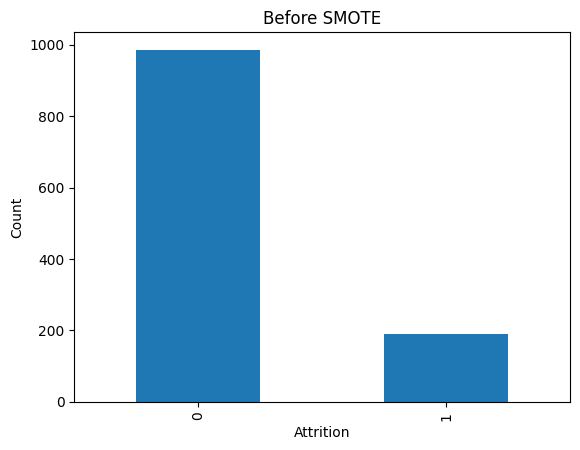

In [32]:
from imblearn.over_sampling import SMOTE
print(y_train.value_counts())
import matplotlib.pyplot as plt

y_train.value_counts().plot(kind="bar")

plt.title("Before SMOTE")
plt.xlabel("Attrition")
plt.ylabel("Count")

plt.show()

Attrition
0    986
1    986
Name: count, dtype: int64


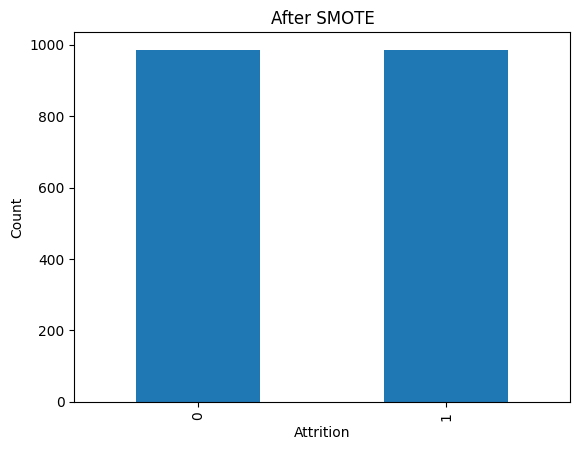

In [33]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)
print(y_train_smote.value_counts())
y_train_smote.value_counts().plot(kind="bar")

plt.title("After SMOTE")
plt.xlabel("Attrition")
plt.ylabel("Count")

plt.show()

In [34]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_smote, y_train_smote)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [35]:
y_pred_rf = rf_model.predict(X_test_scaled)

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_rf))
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.8435374149659864
Precision: 0.52
Recall   : 0.2765957446808511
F1 Score : 0.3611111111111111
ROC AUC  : 0.7993797915410457
[[235  12]
 [ 34  13]]
              precision    recall  f1-score   support

           0       0.87      0.95      0.91       247
           1       0.52      0.28      0.36        47

    accuracy                           0.84       294
   macro avg       0.70      0.61      0.64       294
weighted avg       0.82      0.84      0.82       294



In [36]:
!pip install xgboost

In [37]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_smote,
    y_train_smote
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [38]:
y_pred_xgb = xgb_model.predict(X_test_scaled)

y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:,1]
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall   :", recall_score(y_test, y_pred_xgb))
print("F1 Score :", f1_score(y_test, y_pred_xgb))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_xgb))
cm = confusion_matrix(y_test, y_pred_xgb)

print(cm)
print(classification_report(y_test, y_pred_xgb))

Accuracy : 0.8571428571428571
Precision: 0.6086956521739131
Recall   : 0.2978723404255319
F1 Score : 0.4
ROC AUC  : 0.7789645964338012
[[238   9]
 [ 33  14]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.61      0.30      0.40        47

    accuracy                           0.86       294
   macro avg       0.74      0.63      0.66       294
weighted avg       0.84      0.86      0.84       294



In [39]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

param_dist = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__gamma": [0, 0.1, 0.3, 0.5]
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring="f1",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)

print("Best Parameters:")
print(random_search.best_params_)

best_xgb = random_search.best_estimator_

y_pred_best = best_xgb.predict(X_test_scaled)
y_prob_best = best_xgb.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1 Score :", f1_score(y_test, y_pred_best))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_best))

print(confusion_matrix(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 8, 'model__learning_rate': 0.2, 'model__gamma': 0.1, 'model__colsample_bytree': 1.0}
Accuracy : 0.8571428571428571
Precision: 0.5925925925925926
Recall   : 0.3404255319148936
F1 Score : 0.43243243243243246
ROC AUC  : 0.7906796451029373
[[236  11]
 [ 31  16]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.59      0.34      0.43        47

    accuracy                           0.86       294
   macro avg       0.74      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



In [40]:
y_pred_best = best_xgb.predict(X_test_scaled)
y_prob_best = best_xgb.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1 Score :", f1_score(y_test, y_pred_best))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_best))
cm = confusion_matrix(y_test, y_pred_best)
print(cm)
print(classification_report(y_test, y_pred_best))

Accuracy : 0.8571428571428571
Precision: 0.5925925925925926
Recall   : 0.3404255319148936
F1 Score : 0.43243243243243246
ROC AUC  : 0.7906796451029373
[[236  11]
 [ 31  16]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.59      0.34      0.43        47

    accuracy                           0.86       294
   macro avg       0.74      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



In [41]:
scaler = joblib.load(f"{PROJECT_DIR}/models/scaler.pkl")
preprocessor = joblib.load(f"{PROJECT_DIR}/models/preprocessor.pkl")

joblib.dump(
    best_xgb,
    f"{PROJECT_DIR}/models/final_xgboost.pkl"
)

['/content/drive/MyDrive/Employee-Attrition-Prediction/models/final_xgboost.pkl']

In [42]:
scaler = joblib.load(
    f"{PROJECT_DIR}/models/scaler.pkl"
)

preprocessor = joblib.load(
    f"{PROJECT_DIR}/models/preprocessor.pkl"
)

joblib.dump(
    best_xgb,
    f"{PROJECT_DIR}/models/final_xgboost.pkl"
)

print("Final XGBoost model saved successfully!")

Final XGBoost model saved successfully!


In [50]:
!git remote set-url origin https://github.com/Prabhat-Git111/-Employee-Attrition-Prediction-.git
!git remote -v

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [51]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Employee-Attrition-Prediction"

os.chdir(PROJECT_DIR)

!git init
!git branch -M main

!git remote add origin https://github.com/Prabhat-Git111/-Employee-Attrition-Prediction-.git

!git remote -v

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/drive/MyDrive/Employee-Attrition-Prediction/.git/
origin	https://github.com/Prabhat-Git111/-Employee-Attrition-Prediction-.git (fetch)
origin	https://github.com/Prabhat-Git111/-Employee-Attrition-Prediction-.git (push)


In [52]:
import os

os.chdir("/content/drive/MyDrive/Employee-Attrition-Prediction")

!git status

On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	README.md
	datasets/
	models/
	notebooks/
	requirements.txt

nothing added to commit but untracked files present (use "git add" to track)
